In [1]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Solution model parametrization

LiPF6 (1M) in EC/EMC (3:7)

## Parsing RDF

In [2]:
# --- 1. Define Bulk Densities ---
L_nm = 3.9612724
vol_nm3 = L_nm**3

# Dictionary of bulk densities (particles / nm^3)
bulk_rho = {
    "Li+": 36 / vol_nm3,
    "P(PF6)": 36 / vol_nm3,
    # "F(PF6)": 36*6 / vol_nm3,
    "O(c_EC)": 156 / vol_nm3,
    "O(c_EMC)": 240 / vol_nm3,
}

R_gas = 8.314 # J/mol K
T_sys = 293 # K


# Load Data
rdf_data = pd.read_csv('../data/LiPF6_EC_EMC/rdf/LPF1M_EC-EMC_rdf.csv')


# --- 2. Function for Full Profile (PMF & CN vs r) ---
def calculate_r_profile(r, g, neighbor_species, bulk_densities, T=298.15):
    """
    Calculates PMF and running Coordination Number (CN) over the entire r range.
    
    Parameters:
    - r: Array of radial distances.
    - g: Array of RDF values g(r).
    - neighbor_species: Name of the neighbor species (to lookup density).
    - bulk_densities: Dictionary of densities.
    
    Returns:
    - pmf_profile: Array of PMF values (kJ/mol).
    - cn_profile: Array of cumulative CN values.
    """
    # 1. PMF Profile
    # Handle zeros to avoid log(0)
    with np.errstate(divide='ignore'):
        pmf_profile = -R_gas * T * np.log(g) / 1000.0 # kJ/mol
    # Replace inf with nan or a large number if desired
    pmf_profile[g == 0] = np.inf 

    # 2. Running CN Profile
    # Get density of the NEIGHBOR
    rho_nm3 = bulk_densities.get(neighbor_species)
    if rho_nm3 is None:
        print(f"Warning: Density not found for {neighbor_species}")
        return pmf_profile, np.full_like(r, np.nan)
        
    rho_A3 = rho_nm3 * 0.001 # Convert nm^-3 to A^-3

    # Integrate: n(r) = integral_0^r (4*pi*s^2 * rho * g(s)) ds
    integrand = 4 * np.pi * (r**2) * rho_A3 * g
    
    # Cumulative trapezoidal integration
    # cumtrapz returns array of length N-1, so we prepend 0
    from scipy.integrate import cumulative_trapezoid
    cn_profile = cumulative_trapezoid(integrand, x=r, initial=0)
    
    return pmf_profile, cn_profile

# --- 3. Function for Solvation Shell Extraction (Peak & Cutoff) ---
def extract_solvation_shell_params(df, bulk_densities, T=298.15, manual_cutoffs=None, peak_search_ranges=None):
    """
    Analyzes RDFs to find Peak, Cutoff, and specific Solvation Shell CN.
    Processes both A-B and B-A perspectives for each pair.
    
    Parameters:
    - peak_search_ranges: Dict of {'PairName': (r_min, r_max)} to restrict peak search.
      Example: {"N(TMA)-B(BF4)": (4.0, 6.0)}
    """
    if manual_cutoffs is None:
        manual_cutoffs = {}
    if peak_search_ranges is None:
        peak_search_ranges = {}
        
    r_vals = df['r'].values
    results = []
    
    # Iterate over raw pairs in the CSV
    for pair_col in df.columns:
        if pair_col == 'r':
            continue
            
        g_vals = df[pair_col].values
        
        # Parse the pair name "A-B"
        parts = pair_col.split('-')
        species_A = parts[0]
        species_B = parts[1]
        
        # Determine perspectives to calculate
        perspectives = [(species_A, species_B)]
        if species_A != species_B:
            perspectives.append((species_B, species_A))
            
        for center, neighbor in perspectives:
            
            # 1. Get Density of the NEIGHBOR
            rho_nm3 = bulk_densities.get(neighbor)
            rho_A3 = rho_nm3 * 0.001 if rho_nm3 else np.nan
            
            # 2. Find Peak with Optional Range Restriction
            # Default: Search over full range
            
            # Define indices to search
            valid_indices = np.arange(len(g_vals))
            
            # Apply Range Restriction if defined for this pair
            if pair_col in peak_search_ranges:
                r_min, r_max = peak_search_ranges[pair_col]
                mask = (r_vals >= r_min) & (r_vals <= r_max)
                valid_indices = np.where(mask)[0]
            
            # Subset g(r) for search
            if len(valid_indices) > 0:
                search_g = g_vals[valid_indices]
                # Find peaks in the constrained region
                peaks, _ = find_peaks(search_g, prominence=0.1)
            else:
                peaks = []
            
            if len(peaks) > 0:
                # Map local peak index back to global index
                peak_true = "Yes"
                local_peak_idx = peaks[0]
                global_peak_idx = valid_indices[local_peak_idx]
                
                r_peak = r_vals[global_peak_idx]
                g_peak = g_vals[global_peak_idx]
                
                # PMF at peak
                R_gas = 8.314
                pmf_val = -R_gas * T * np.log(g_peak) / 1000.0 if g_peak > 0 else np.inf
                
                # 3. Determine Cutoff
                # Check manual override
                cutoff_r = np.nan
                cutoff_method = "Auto"
                
                if pair_col in manual_cutoffs:
                    cutoff_r = manual_cutoffs[pair_col]
                    cutoff_idx = (np.abs(r_vals - cutoff_r)).argmin()
                    cutoff_method = "Manual"
                else:
                    # Auto detection (First minimum after peak)
                    cutoff_idx = -1
                    found_min = False
                    # Search from the peak onwards
                    for i in range(global_peak_idx, len(g_vals) - 1):
                        if g_vals[i+1] > g_vals[i]: 
                            cutoff_idx = i
                            found_min = True
                            break
                    
                    if found_min:
                        cutoff_r = r_vals[cutoff_idx]
                    else:
                        cutoff_method = "Failed"
                
                # 4. Integrate CN
                if not np.isnan(cutoff_r) and not np.isnan(rho_A3):
                    r_slice = r_vals[:cutoff_idx+1]
                    g_slice = g_vals[:cutoff_idx+1]
                    integrand = 4 * np.pi * (r_slice**2) * rho_A3 * g_slice
                    cn_val = np.trapz(integrand, x=r_slice)
                else:
                    cn_val = np.nan
                    
            else:
                # No peak found
                peak_true = "No Peak"
                r_peak, g_peak, pmf_val, cutoff_r, cn_val = np.nan, np.nan, np.nan, np.nan, 0.0
                cutoff_method = "No Peak"

                if pair_col in manual_cutoffs:
                    cutoff_r = manual_cutoffs[pair_col]
                    cutoff_idx = (np.abs(r_vals - cutoff_r)).argmin()
                    cutoff_method = "Manual"
                    
                    if not np.isnan(cutoff_r) and not np.isnan(rho_A3):
                        r_slice = r_vals[:cutoff_idx+1]
                        g_slice = g_vals[:cutoff_idx+1]
                        integrand = 4 * np.pi * (r_slice**2) * rho_A3 * g_slice
                        cn_val = np.trapz(integrand, x=r_slice)
                    else:
                        cn_val = np.nan
            
            results.append({
                "Original_Pair": pair_col,
                "Center_Species": center,
                "Neighbor_Species": neighbor,
                "X_neighbor": bulk_densities.get(neighbor, 0) / sum(bulk_densities.values()),
                "Peak_exist": peak_true,
                "Peak_r (Angstrom)": r_peak,
                "Peak_gr": g_peak,
                "PMF_well_depth (kJ/mol)": pmf_val,
                "Cutoff_Used (Å)": cutoff_r,
                "Method": cutoff_method,
                "CN": cn_val
            })

    res_df = pd.DataFrame(results)
    res_df.sort_values(by=['Center_Species', 'Neighbor_Species'], inplace=True)
    return res_df

In [3]:
# --- Setup Colors and Species ---
species_list = bulk_rho.keys()
colors_list = ['tab:purple', 'cyan', 'dodgerblue', 'crimson'] # Used hotpink for better visibility than 'pink'
SPECIES_COLOR = dict(zip(species_list, colors_list))

# --- Helper to find Data Column ---
def get_pair_data(df, sp1, sp2):
    # Try A-B
    if f"{sp1}-{sp2}" in df.columns:
        return df[f"{sp1}-{sp2}"], False # False = not flipped
    # Try B-A
    elif f"{sp2}-{sp1}" in df.columns:
        return df[f"{sp2}-{sp1}"], True # True = flipped (order reversed in name)
    return None, False

def bulk_rho_to_molar(bulk_rho):
    # Convert bulk density (particles/nm^3) to molar density (mol/L)
    NA = 6.0221408e23 # Avogadro's number
    molar_rho = {}
    for species, density in bulk_rho.items():
        # Convert to mol/L
        molar_density = density / NA * (1e24) # 1e24 nm^3/L
        molar_rho[species] = molar_density
    return molar_rho



In [4]:
# --- 4. Execution Example ---

# Optional Overrides
my_cutoffs = {
    "Li+-Li+": 5.0, 
    "P(PF6)-P(PF6)": 5.0,
    "O(c_EMC)-P(PF6)": 7.5,
    "O(c_EC)-P(PF6)": 8.0,
}

peak_ranges = {
    "Li+-Li+": (2.0, 6.0),
    "P(PF6)-P(PF6)": (2.0, 6.0),
    "O(c_EMC)-P(PF6)": (6.0, 8.0),
    "O(c_EC)-P(PF6)": (6.0, 8.0),
}

# A. Get Summary Table
summary_table = extract_solvation_shell_params(rdf_data, bulk_rho, manual_cutoffs=my_cutoffs, peak_search_ranges=peak_ranges)

# Display Summary
pd.set_option('display.max_columns', None)
print("Solvation Shell Analysis (Sorted by Center):")
display(summary_table)

# Optional: Save to CSV
summary_table.to_csv('../data/LiPF6_EC_EMC/processed/rdf_shell_analysis.csv', index=False)


Solvation Shell Analysis (Sorted by Center):


C:\Users\Chaoxuan Gu\AppData\Local\Temp\ipykernel_536\1362954568.py:167: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  cn_val = np.trapz(integrand, x=r_slice)
C:\Users\Chaoxuan Gu\AppData\Local\Temp\ipykernel_536\1362954568.py:186: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  cn_val = np.trapz(integrand, x=r_slice)


,Original_Pair,Center_Species,Neighbor_Species,X_neighbor,Peak_exist,Peak_r (Angstrom),Peak_gr,PMF_well_depth (kJ/mol),Cutoff_Used (Å),Method,CN
17,Li+-F(PF6),F(PF6),Li+,0.076923,Yes,2.1,3.138297,-2.834977,3.1,Auto,0.098652
16,Li+-F(PF6),Li+,F(PF6),0.000000,Yes,2.1,3.138297,-2.834977,3.1,Auto,NaN
3,Li+-Li+,Li+,Li+,0.076923,No Peak,NaN,NaN,NaN,5.0,Manual,0.012596
0,Li+-O(c_EC),Li+,O(c_EC),0.333333,Yes,2.1,37.853955,-9.007373,3.5,Auto,2.364649
4,Li+-O(c_EMC),Li+,O(c_EMC),0.512821,Yes,2.1,19.222448,-7.327585,3.3,Auto,1.806429
7,Li+-P(PF6),Li+,P(PF6),0.076923,Yes,3.3,3.890486,-3.367560,4.9,Auto,0.418251
1,Li+-O(c_EC),O(c_EC),Li+,0.076923,Yes,2.1,37.853955,-9.007373,3.5,Auto,0.545688
2,O(c_EC)-O(c_EC),O(c_EC),O(c_EC),0.333333,Yes,3.1,3.747271,-3.274589,5.1,Auto,1.677913
15,O(c_EMC)-O(c_EC),O(c_EC),O(c_EMC),0.512821,Yes,3.1,2.257313,-2.018193,4.5,Auto,1.397918
10,O(c_EC)-P(PF6),O(c_EC),P(PF6),0.076923,Yes,7.5,1.974065,-1.685832,8.0,Manual,1.367916


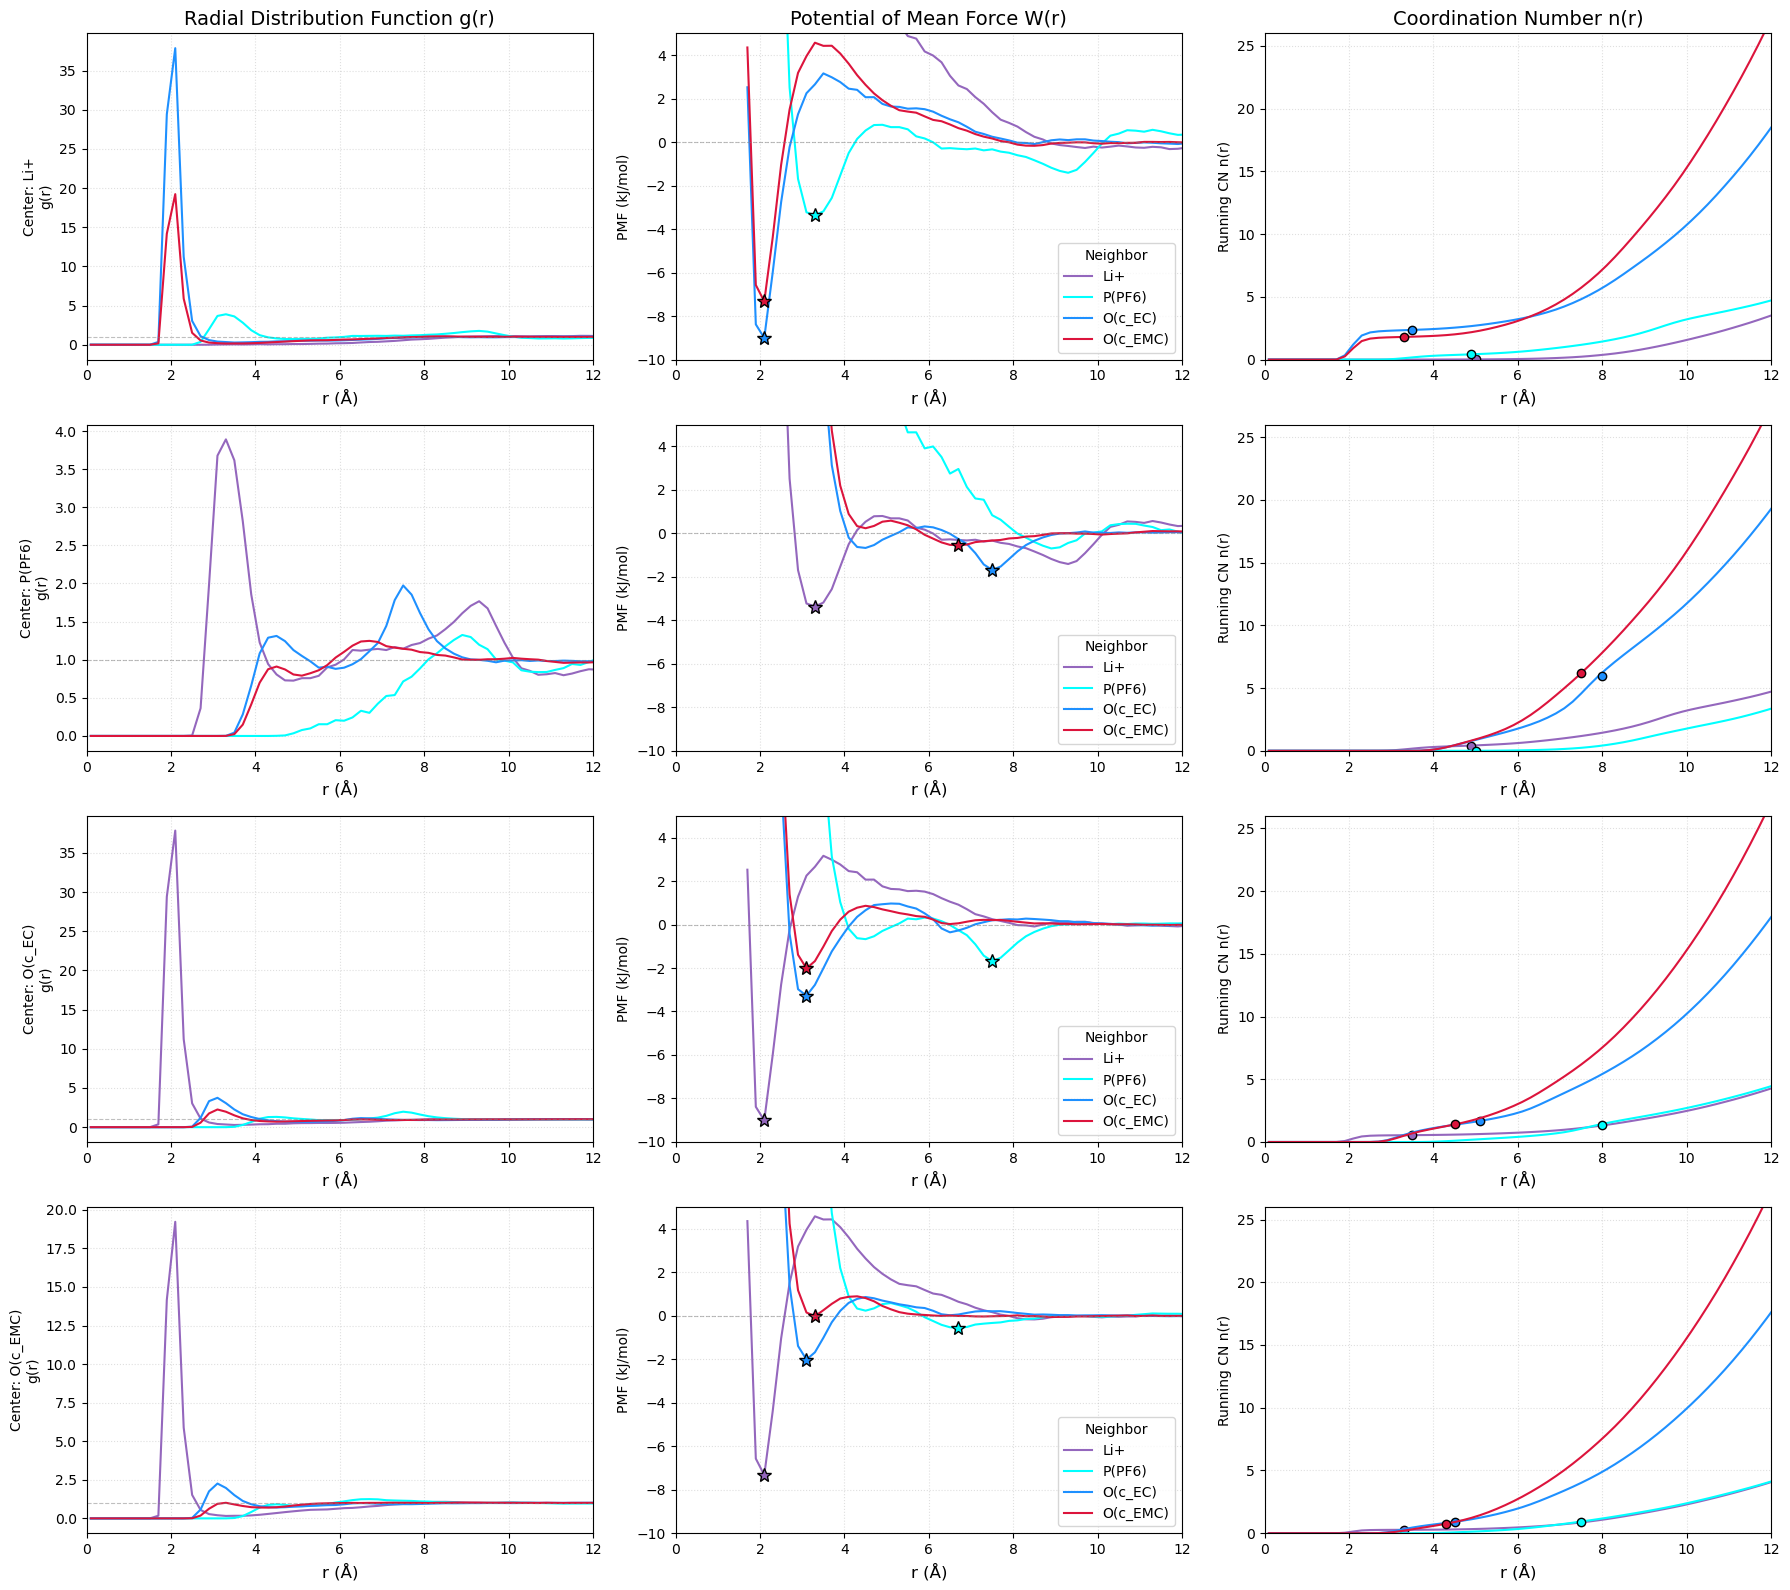

In [5]:

# --- Generate the Figure ---
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 16), sharex=False)
r_vals = rdf_data['r']

# Iterate over Centers (Rows)
for i, center in enumerate(species_list):
    
    # Iterate over Neighbors (Curves)
    for neighbor in species_list:
        color = SPECIES_COLOR[neighbor]
        
        # A. Get Raw RDF Data
        g_vals_raw, is_flipped = get_pair_data(rdf_data, center, neighbor)
        
        if g_vals_raw is None:
            continue
            
        # B. Calculate Profiles
        # Note: calculate_r_profile handles the "Neighbor Density" logic automatically
        pmf_profile, cn_profile = calculate_r_profile(r_vals.values, g_vals_raw.values, neighbor, bulk_rho)
        
        # C. Get Scalar Params for Annotation (Peak & Cutoff)
        # We query the summary_table generated in the previous step
        row_stats = summary_table[
            (summary_table['Center_Species'] == center) & 
            (summary_table['Neighbor_Species'] == neighbor)
        ]
        
        # Plot 1: RDF
        ax_rdf = axes[i, 0]
        ax_rdf.plot(r_vals, g_vals_raw, color=color, label=neighbor, linewidth=1.5)
        
        # Plot 2: PMF
        ax_pmf = axes[i, 1]
        ax_pmf.plot(r_vals, pmf_profile, color=color, label=neighbor, linewidth=1.5)
        
        # Plot 3: CN
        ax_cn = axes[i, 2]
        ax_cn.plot(r_vals, cn_profile, color=color, label=neighbor, linewidth=1.5)
        
        # --- Annotations ---
        if not row_stats.empty:
            # 1. PMF Peak (Minimum Energy)
            r_peak = row_stats.iloc[0]['Peak_r (Angstrom)']
            w_peak = row_stats.iloc[0]['PMF_well_depth (kJ/mol)']
            
            if not np.isnan(r_peak) and not np.isnan(w_peak):
                ax_pmf.plot(r_peak, w_peak, marker='*', markersize=10, 
                            color=color, markeredgecolor='black', linestyle='None')
            
            # 2. CN Cutoff
            r_cut = row_stats.iloc[0]['Cutoff_Used (Å)']
            cn_val = row_stats.iloc[0]['CN']
            
            if not np.isnan(r_cut) and not np.isnan(cn_val):
                # We need the y-value of the curve at r_cut to plot the marker ON the line
                # (cn_val is the integration result, which should match the curve at r_cut)
                ax_cn.plot(r_cut, cn_val, marker='o', markersize=6, 
                           color=color, markeredgecolor='black', linestyle='None')

    # Row Formatting
    # RDF
    axes[i, 0].set_ylabel(f"Center: {center}\ng(r)")
    axes[i, 0].axhline(1, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    # axes[i, 0].set_ylim(-0.5, 4.5)
    
    # PMF
    axes[i, 1].set_ylabel("PMF (kJ/mol)")
    axes[i, 1].axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    axes[i, 1].set_ylim(-10, 5) # Zoom in on the wells
    axes[i, 1].legend(title="Neighbor", fontsize=10, loc='lower right')

    # CN
    axes[i, 2].set_ylabel("Running CN n(r)")
    axes[i, 2].set_ylim(0, 26)

    # X-Axis Labels (Bottom Row only)
    axes[i, 0].set_xlabel("r (Å)", fontsize=12)
    axes[i, 1].set_xlabel("r (Å)", fontsize=12)
    axes[i, 2].set_xlabel("r (Å)", fontsize=12)

    axes[i, 0].set_xlim(0, 12)
    axes[i, 1].set_xlim(0, 12)
    axes[i, 2].set_xlim(0, 12)

    axes[i, 0].grid(True, linestyle=':', alpha=0.4)
    axes[i, 1].grid(True, linestyle=':', alpha=0.4)
    axes[i, 2].grid(True, linestyle=':', alpha=0.4)

# Titles (Top Row only)
axes[0, 0].set_title("Radial Distribution Function g(r)", fontsize=14)
axes[0, 1].set_title("Potential of Mean Force W(r)", fontsize=14)
axes[0, 2].set_title("Coordination Number n(r)", fontsize=14)

plt.tight_layout()
# plt.savefig('rdf_pmf_cn_summary.png', dpi=300)
plt.show()

## RDF to $a_{ij}$

In [6]:
def get_affinity_from_peak(summary_df, species_order):
    """
    Constructs the symmetric Affinity Matrix (a_ij) directly from RDF Peaks.
    Assumption: a_ij = Peak_g(r). If no peak exists, a_ij = 1.0 (Random Mixing).
    """
    n = len(species_order)
    a_matrix = np.zeros((n, n))
    
    # Helper to lookup peak in the dataframe
    def lookup_peak(s1, s2):
        # Check A-B
        row = summary_df[(summary_df['Center_Species'] == s1) & 
                         (summary_df['Neighbor_Species'] == s2)]
        if not row.empty:
            return row.iloc[0]['Peak_gr']
        return np.nan

    for i in range(n):
        for j in range(n):
            sp_i = species_order[i]
            sp_j = species_order[j]
            
            # 1. Get raw peaks from both perspectives
            val_ij = lookup_peak(sp_i, sp_j) # i looking at j
            val_ji = lookup_peak(sp_j, sp_i) # j looking at i
            
            # 2. Determine consensus value
            # If diagonal (i=i)
            if i == j:
                if not pd.isna(val_ij) and val_ij >= 0.1:
                    a_matrix[i, j] = val_ij
                else:
                    a_matrix[i, j] = 1.0 # Default for self if no peak
            
            # If off-diagonal
            else:
                # Symmetrize: Average available peaks
                peaks = []
                if not pd.isna(val_ij) and val_ij >= 0.1:
                    peaks.append(val_ij)
                else:
                    peaks.append(1.0) # Default for self if no peak
                
                if not pd.isna(val_ji) and val_ji >= 0.1:
                    peaks.append(val_ji)
                else:
                    peaks.append(1.0) # Default for self if no peak
                
                if len(peaks) > 0:
                    a_matrix[i, j] = sum(peaks) / len(peaks)
                else:
                    a_matrix[i, j] = 1.0 # Default random mixing
                    
    return a_matrix

def calculate_local_theta(a_matrix, X_vec):
    """
    Calculates the Local Neighbor Fractions (theta_j|i) given Affinities and Composition.
    Formula: theta_j|i = (X_j * a_ji) / sum_k(X_k * a_ki)
    """
    n = len(X_vec)
    theta_matrix = np.zeros((n, n))
    Lambda_vec = np.zeros(n) # Local partition functions
    
    for i in range(n): # Center species i
        # 1. Calculate Lambda_i (Partition Function)
        # Sum over neighbors k: X_k * a_ki
        # Since a is symmetric, a_ki = a_ik, so we can use row i
        Lambda_i = 0.0
        for k in range(n):
            Lambda_i += X_vec[k] * a_matrix[k, i]
        
        Lambda_vec[i] = Lambda_i
        
        # 2. Calculate Theta_j|i
        for j in range(n): # Neighbor species j
            numerator = X_vec[j] * a_matrix[j, i]
            theta_matrix[i, j] = numerator / Lambda_i
            
    return theta_matrix, Lambda_vec

def get_molar_fractions_from_rho(bulk_densities):
    """
    Converts bulk densities to molar fractions.
    """
    total_density = sum(bulk_densities.values())
    X_dict = {}
    for species in bulk_densities.keys():
        X_dict[species] = bulk_densities[species] / total_density
    return X_dict

def get_molar_concentrations_from_rho(bulk_densities):
    """
    Converts bulk densities (particles/nm^3) to molar concentrations (mol/L).
    """
    NA = 6.0221408e23 # Avogadro's number
    molar_conc = {}
    for species, density in bulk_densities.items():
        # Convert to mol/L
        molar_conc[species] = density / NA * (1e24) # 1e24 nm^3/L
    return molar_conc


In [7]:
# --- Setup ---
# Load your summary dataframe (ensure it's loaded from previous steps)
# summary_df = ... 

species_list = ['Li+', 'P(PF6)', 'O(c_EC)', 'O(c_EMC)']
species_labels = ['Li+', 'PF6-', 'EC', 'EMC']

# 1. Define Mole Fractions (X)
# We can extract them from the dataframe or define manually for precision
X_dict = get_molar_fractions_from_rho(bulk_rho)
X_vec = np.array([X_dict[sp] for sp in species_list])

# molar concentrations (if needed for other calculations)
molar_conc = get_molar_concentrations_from_rho(bulk_rho)

# --- Step 1: Get Affinity Matrix (a_ij) ---
a_raw = get_affinity_from_peak(summary_table, species_list)

# --- Inspection ---
print("--- 1. Mole Fractions (X) and concentration (mol/L) ---")
print(pd.Series(X_vec, index=species_labels))
print("\n--- Molar Concentrations (mol/L) ---")
print(pd.Series(molar_conc, index=species_labels))

print("\n--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---")
df_a = pd.DataFrame(a_raw, index=species_labels, columns=species_labels)
print(df_a.round(2))

--- 1. Mole Fractions (X) and concentration (mol/L) ---
Li+     0.076923
PF6-    0.076923
EC      0.333333
EMC     0.512821
dtype: float64

--- Molar Concentrations (mol/L) ---
Li+     0.961717
PF6-         NaN
EC           NaN
EMC          NaN
dtype: float64

--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---
        Li+  PF6-     EC    EMC
Li+    1.00  3.89  37.85  19.22
PF6-   3.89  1.00   1.97   1.25
EC    37.85  1.97   3.75   2.26
EMC   19.22  1.25   2.26   1.01


In [8]:
a_robust = a_raw

print("\n--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---")
df_a = pd.DataFrame(a_raw, index=species_labels, columns=species_labels)
print(df_a.round(2))


--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---
        Li+  PF6-     EC    EMC
Li+    1.00  3.89  37.85  19.22
PF6-   3.89  1.00   1.97   1.25
EC    37.85  1.97   3.75   2.26
EMC   19.22  1.25   2.26   1.01


In [9]:
# print delta epsilon matrix
delta_epsilon = -R_gas*T_sys * np.log(a_raw) /1000  # kJ/mol
print("\n--- Delta Epsilon Matrix ( RT * -ln(a_ij) kJ/mol) ---")
df_de = pd.DataFrame(delta_epsilon, index=species_labels, columns=species_labels)
print(df_de.round(2))


--- Delta Epsilon Matrix ( RT * -ln(a_ij) kJ/mol) ---
       Li+  PF6-    EC   EMC
Li+  -0.00 -3.31 -8.85 -7.20
PF6- -3.31 -0.00 -1.66 -0.54
EC   -8.85 -1.66 -3.22 -1.98
EMC  -7.20 -0.54 -1.98 -0.02


In [10]:
# --- Step 2: Get Local Fractions (theta) ---
theta_model, Lambda_vals = calculate_local_theta(a_raw, X_vec)


print("\n--- 3. Local Partition Functions (Lambda_i) ---")
print(pd.Series(Lambda_vals, index=species_labels))

print("\n--- 4. Model Local Fractions (theta_j|i) ---")
# Rows = Center, Cols = Neighbor
df_theta = pd.DataFrame(theta_model, index=species_labels, columns=species_labels)
print(df_theta.round(4))


--- 3. Local Partition Functions (Lambda_i) ---
Li+     22.851842
PF6-     1.673917
EC       5.470380
EMC      2.845007
dtype: float64

--- 4. Model Local Fractions (theta_j|i) ---
         Li+    PF6-      EC     EMC
Li+   0.0034  0.0131  0.5522  0.4314
PF6-  0.1788  0.0460  0.3931  0.3822
EC    0.5323  0.0278  0.2283  0.2116
EMC   0.5197  0.0337  0.2645  0.1821


In [11]:
# --- 1. Function to Calculate MD Theta ---
def get_md_theta(summary_df, species_order):
    """
    Calculates the Local Neighbor Fractions (theta_j|i) directly from MD Counts.
    Formula: theta_j|i = N_ji / sum_k(N_ki)
    """
    n = len(species_order)
    theta_MD = np.zeros((n, n))
    
    # Fill Counts Matrix N_ij
    N_matrix = np.zeros((n, n))
    
    for idx, row in summary_df.iterrows():
        c = row['Center_Species']
        ne = row['Neighbor_Species']
        
        if c in species_order and ne in species_order:
            i = species_order.index(c)
            j = species_order.index(ne)
            N_matrix[i, j] = row['CN']
            
    # Apply Floor to Self-Coordination (consistent with model fitting logic)
    # This prevents division by zero for species with no self-interaction
    # for i in range(n):
    #     if N_matrix[i, i] < 0.01:
    #         N_matrix[i, i] = 0.01
            
    # Normalize Rows to get Theta
    # axis=1 sums over neighbors (columns) for each center (row)
    row_sums = N_matrix.sum(axis=1, keepdims=True)
    
    # Avoid div by zero if a species has absolutely no neighbors (unlikely)
    row_sums[row_sums == 0] = 1.0 
    
    theta_MD = N_matrix / row_sums
    
    return theta_MD


# --- 2. Function to Calculate MD CN total ---
def get_md_tot_CN(summary_df, species_order):
    """
    Calculates the Local Neighbor Fractions (theta_j|i) directly from MD Counts.
    Formula: theta_j|i = N_ji / sum_k(N_ki)
    """
    n = len(species_order)
    theta_MD = np.zeros((n, n))
    
    # Fill Counts Matrix N_ij
    N_matrix = np.zeros((n, n))
    
    for idx, row in summary_df.iterrows():
        c = row['Center_Species']
        ne = row['Neighbor_Species']
        
        if c in species_order and ne in species_order:
            i = species_order.index(c)
            j = species_order.index(ne)
            N_matrix[i, j] = row['CN']
            
    # Apply Floor to Self-Coordination (consistent with model fitting logic)
    # This prevents division by zero for species with no self-interaction
    # for i in range(n):
    #     if N_matrix[i, i] < 0.01:
    #         N_matrix[i, i] = 0.01
            
    # Normalize Rows to get Theta
    # axis=1 sums over neighbors (columns) for each center (row)
    row_sums = N_matrix.sum(axis=1)
    
    return row_sums


In [12]:

# --- 2. Execution ---

# Ensure inputs are ready from previous steps
# species_list = ['Li+', 'P(PF6)', 'O(c_EC)', 'O(c_EMC)']
# summary_df, theta_model (from Peak-Based calculation) are needed.

# Recalculate if needed (using your previous functions)
# a_raw = get_affinity_from_peak(summary_df, species_list)
# theta_model, _ = calculate_local_theta(a_raw, X_vec)

theta_MD = get_md_theta(summary_table, species_list)
CN_tot_MD = get_md_tot_CN(summary_table, species_list)
print("\n--- 4. MD Local Fractions (theta_j|i) ---")
# Rows = Center, Cols = Neighbor
df_theta = pd.DataFrame(theta_MD, index=species_labels, columns=species_labels)
print(df_theta.round(4))


print("\n--- 5. Total CN of i ---")
print(pd.Series(CN_tot_MD, index=species_labels))
print("\n--- 5.1. Local Partition Functions (Lambda_i) ---")
print(pd.Series(Lambda_vals, index=species_labels))



--- 4. MD Local Fractions (theta_j|i) ---
         Li+    PF6-      EC     EMC
Li+   0.0027  0.0909  0.5138  0.3925
PF6-  0.0334  0.0001  0.4729  0.4937
EC    0.1094  0.2742  0.3363  0.2802
EMC   0.0946  0.3240  0.3171  0.2643

--- 5. Total CN of i ---
Li+      4.601925
PF6-    12.535707
EC       4.989435
EMC      2.865329
dtype: float64

--- 5.1. Local Partition Functions (Lambda_i) ---
Li+     22.851842
PF6-     1.673917
EC       5.470380
EMC      2.845007
dtype: float64


In [13]:
def generate_full_comsol_txt(df_a, cn_data, species, filename="COMSOL_GMS_Parameters.txt", T_sys=298.15):
    lines = []
    n = len(species)
    
    # --- Section 1: Coordination Numbers (Z) ---
    lines.append("// Coordination Numbers")
    for i, label in enumerate(species, 1):
        # Using .loc ensures we look up the string label in the Pandas Series
        # float() ensures we don't pass a numpy object into the string
        val = float(cn_data.loc[label]) if isinstance(cn_data, pd.Series) else float(cn_data[i])
        lines.append(f"Z{i} {val:.6f} \"Total CN of {label}\"")
    
    # --- Section 2: Affinities (a_ij) ---
    lines.append("\n// Affinity Parameters")
    for i in range(1, n + 1):
        for j in range(1, n + 1):
            name = f"a_{i}{j}"
            if i > j:
                lines.append(f"{name} a_{j}{i} \"Symmetry {species[i-1]}-{species[j-1]}\"")
            else:
                val = df_a.iloc[i-1, j-1]
                lines.append(f"{name} {val:.1f} \"Affinity {species[i-1]}-{species[j-1]}\"")

    # --- Section 3: Energy Differences (de_ij) ---
    lines.append("\n// Energy Parameters (de_ij = -RT*ln(a_ij))")
    R_gas = 8.314 # J/mol K
    
    for i in range(1, n + 1):
        for j in range(1, n + 1):
            name = f"de_{i}{j}"
            if i > j:
                lines.append(f"{name} de_{j}{i} \"Symmetry energy {species[i-1]}-{species[j-1]}\"")
            else:
                # affinity = df_a.iloc[i-1, j-1]
                # Calculate de_ij = -ln(a_ij)
                # val = R_gas * T_sys * -np.log(affinity) if affinity > 0 else 0.0
                lines.append(f"{name} -(R_const*T0)*log(a_{i}{j}) \"Energy diff {species[i-1]}-{species[j-1]}\"")

    # Save file
    with open(filename, 'w') as f:
        f.write("\n".join(lines))
    print(f"Full parameters file '{filename}' generated.")

generate_full_comsol_txt(df_a, pd.Series(CN_tot_MD, index=species_labels), species_labels, filename="../data/LiPF6_EC_EMC/processed/COMSOL_GMS_Parameters.txt")

Full parameters file '../data/LiPF6_EC_EMC/processed/COMSOL_GMS_Parameters.txt' generated.


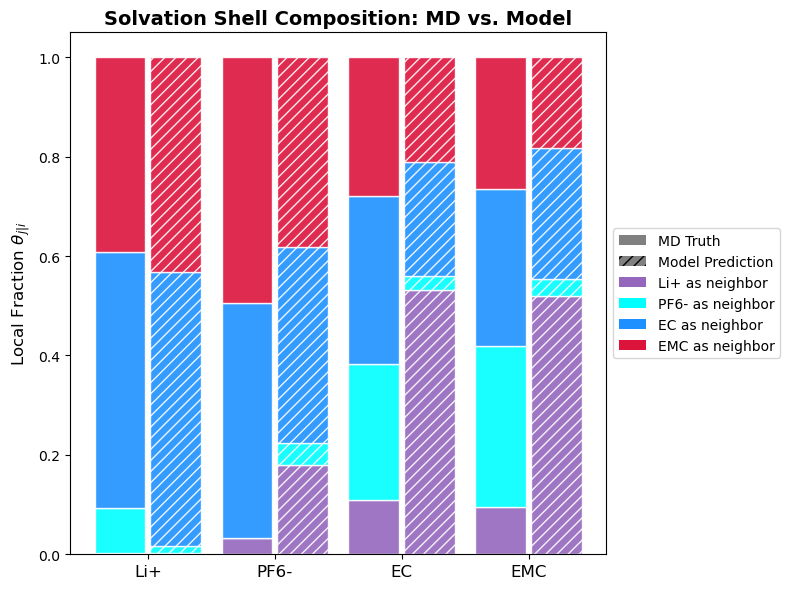

In [14]:
# --- Visualization (Stacked Bar Plot) ---

# Setup
species_labels = ['Li+', 'PF6-', 'EC', 'EMC']
colors = ['tab:purple', 'cyan', 'dodgerblue', 'crimson']
n_species = len(species_list)

fig, ax = plt.subplots(figsize=(8, 6))

# X positions
indices = np.arange(n_species)
width = 0.4

# We plot segments for each NEIGHBOR type
# We need to loop over neighbors (0..4) and stack them
bottom_MD = np.zeros(n_species)
bottom_Model = np.zeros(n_species)

for j in range(n_species):
    neighbor_label = species_labels[j]
    color = colors[j]
    
    # Data for this neighbor layer across all centers
    layer_MD = theta_MD[:, j]
    layer_Model = theta_model[:, j]
    
    # Plot MD Bar (Left)
    ax.bar(indices - width/2 - 0.02, layer_MD, width, 
           bottom=bottom_MD, color=color, label=neighbor_label if j==0 else "", edgecolor='white', alpha=0.9)
    
    # Plot Model Bar (Right)
    # We use hatching '//' to distinguish Model from MD
    ax.bar(indices + width/2 + 0.02, layer_Model, width, 
           bottom=bottom_Model, color=color, hatch='///', edgecolor='white', alpha=0.9)
    
    # Update bottoms
    bottom_MD += layer_MD
    bottom_Model += layer_Model

# Custom Legend to explain the Split Bars
# We create dummy handles
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='gray', label='MD Truth'),
                   Patch(facecolor='gray', hatch='///', label='Model Prediction')]

# Add Neighbor Colors to Legend
for j, label in enumerate(species_labels):
    legend_elements.append(Patch(facecolor=colors[j], label=f'{label} as neighbor'))

# Formatting
ax.set_ylabel('Local Fraction $\\theta_{j|i}$', fontsize=12)
ax.set_title('Solvation Shell Composition: MD vs. Model', fontsize=14, fontweight='bold')
ax.set_xticks(indices)
ax.set_xticklabels(species_labels, fontsize=12)
ax.set_ylim(0, 1.05) # Little headroom
# ax.set_xlim(-0.6, n_species - 0.4)

# Add "MD" and "Model" labels under the first group to guide reader
# ax.text(indices[0] - width/2, -0.02, "MD", ha='center', fontsize=10, fontweight='light')
# ax.text(indices[0] + width/2, -0.02, "Model", ha='center', fontsize=10, fontweight='light')

ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
# plt.savefig('Solvation_Model_Theta_vsMD_LPF-EC-EMC.png', dpi=330)
plt.show()

# Figure 2, MD EDL data from Wu et al. JACS 2023

MD Data Summary:
   Charge_Density_abs  Ratio_EC_EMC
0                 0.0      0.323529
1                 0.4      1.428571
2                 0.6      1.260870
3                 0.8      1.391304
4                 1.2      1.850000

COMSOL Data Summary:
   sigma_abs     Ratio
0   0.002673  0.649189
1   0.199178  0.589848
2   0.394296  0.618808
3   0.597617  0.760227
4   0.800110  1.026769
5   1.187067  1.999262


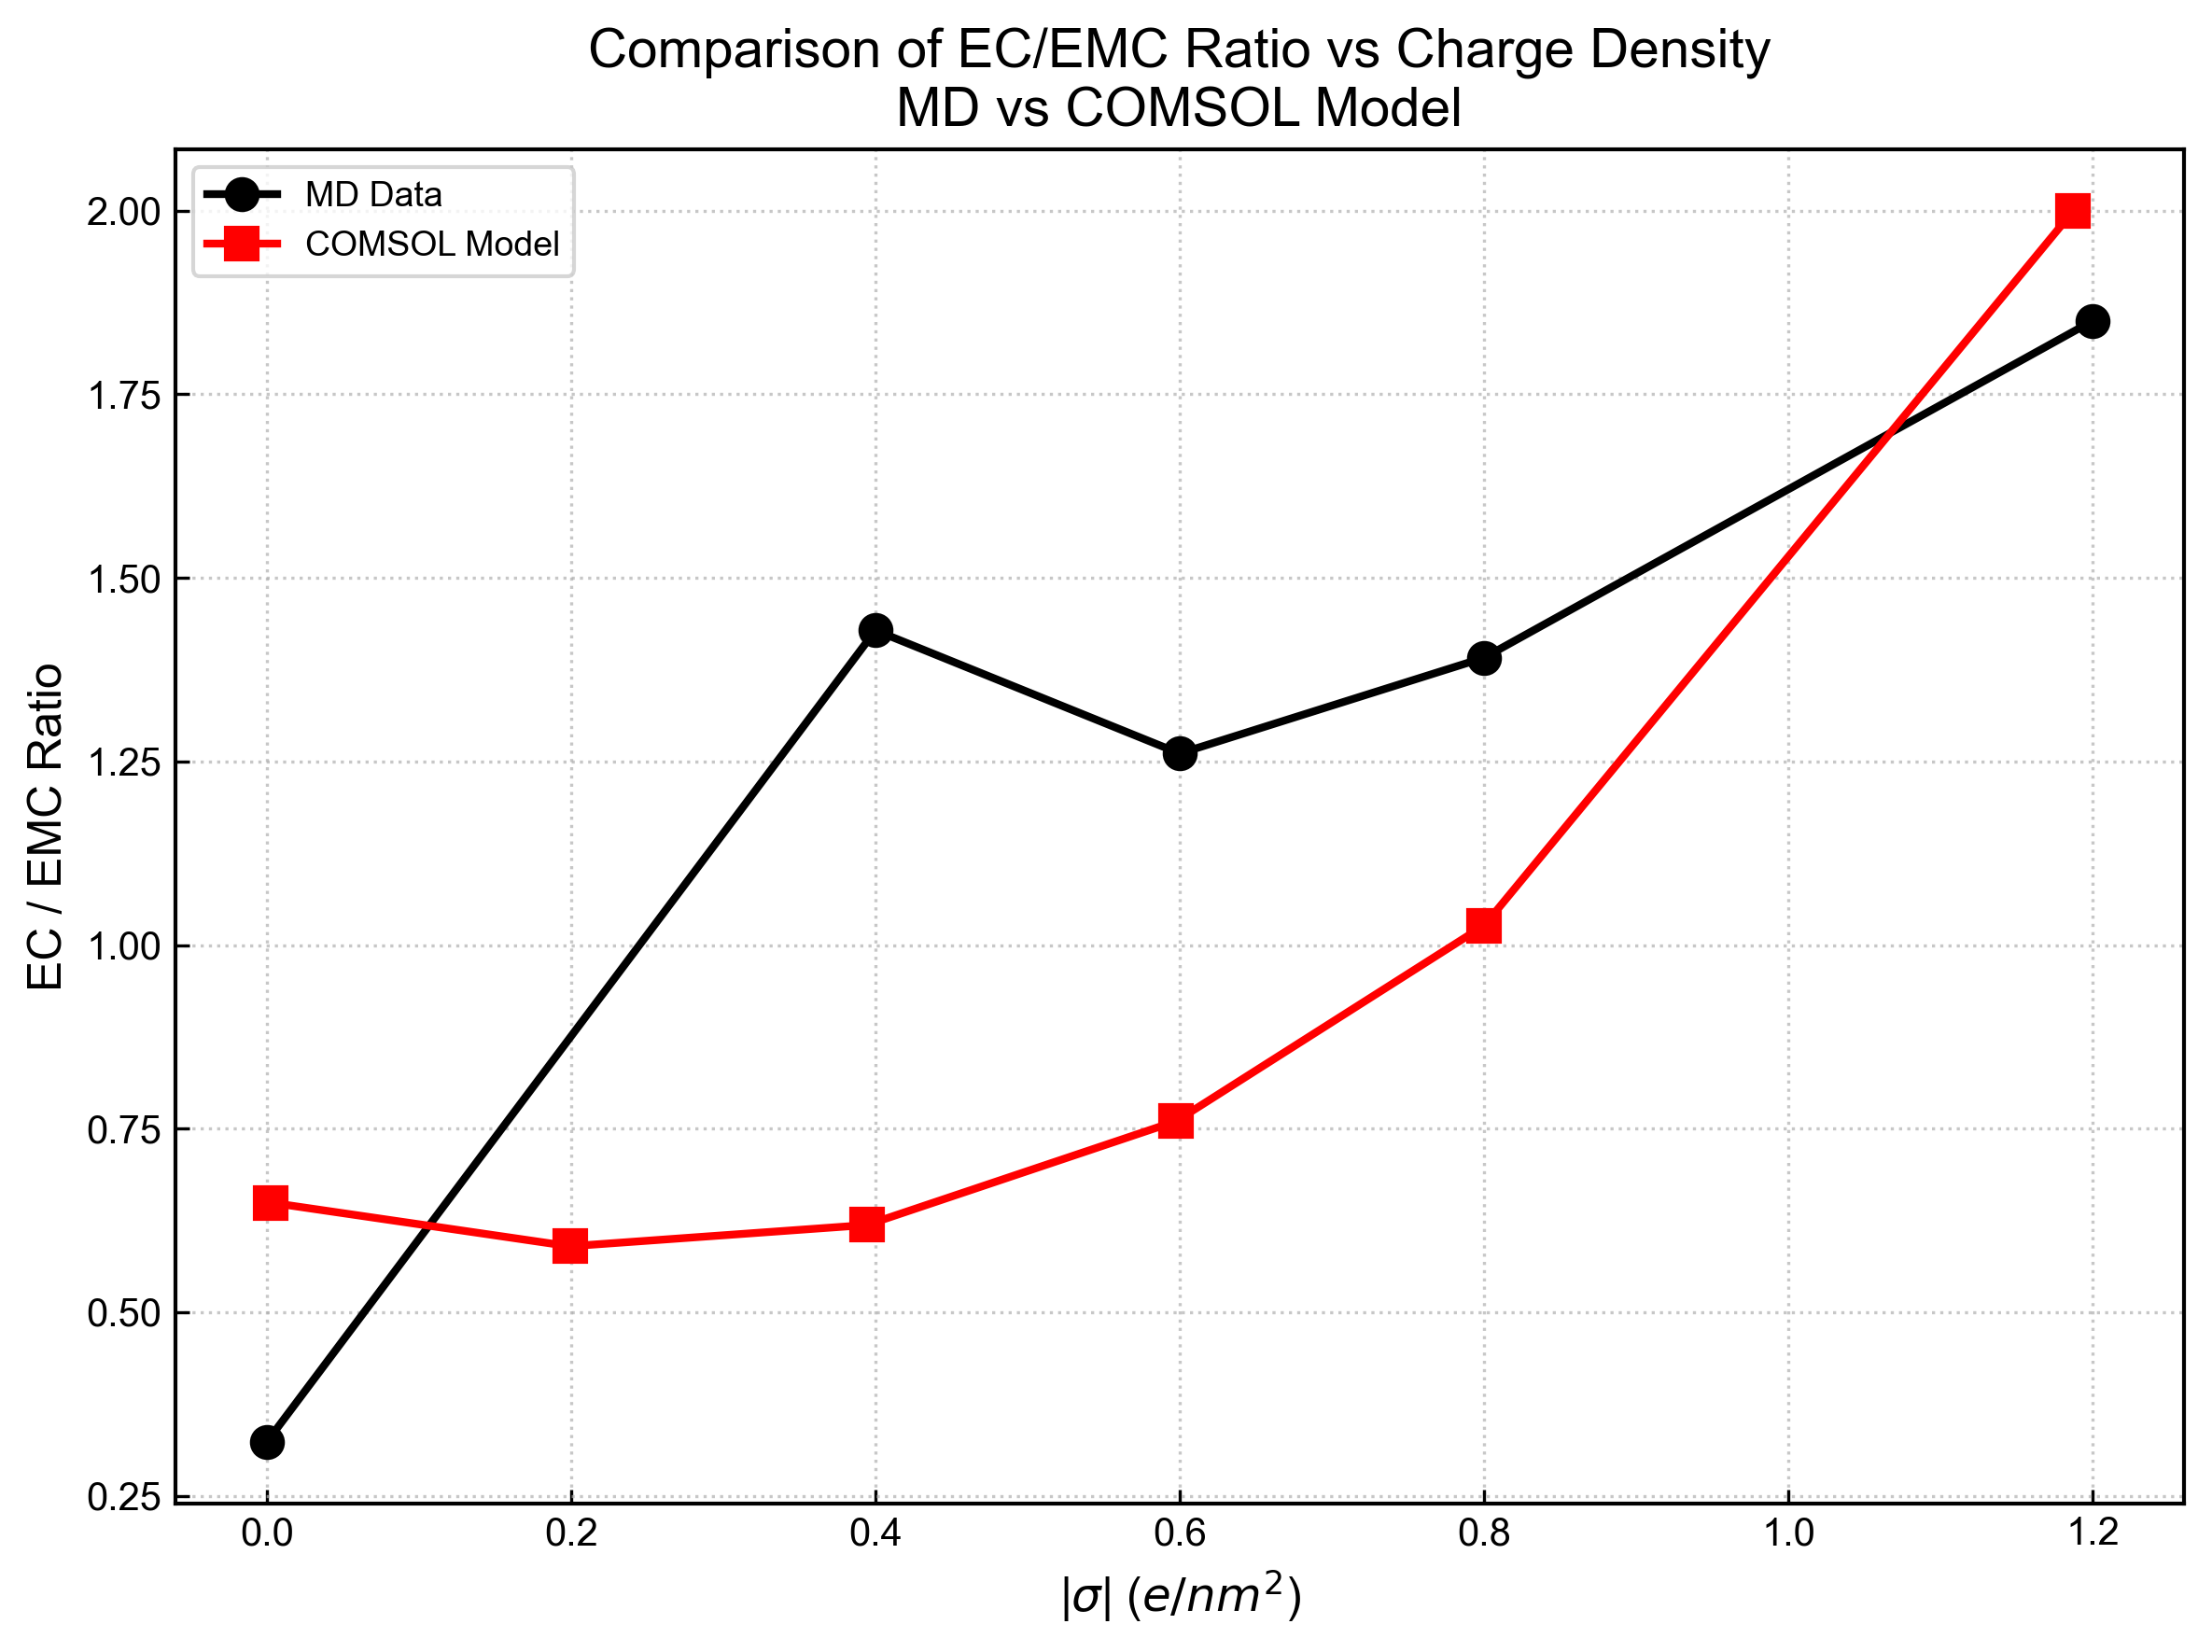

In [16]:
# ---------------------------------------------------------
# 1. MD Data (from Figure 2a of https://doi.org/10.1021/jacs.2c11807)
# ---------------------------------------------------------
# Data for Figure 2a: LiPF6@EC:EMC
# Columns: Charge Density | Li+-coord EC | Free EC | Li+-coord EMC | Free EMC
md_data_source = {
    "Charge_Density_abs": [0.0, 0.4, 0.6, 0.8, 1.2],
    "Li_coordinated_EC": [0.0, 15.0, 16.0, 23.0, 23.0],
    "Free_EC": [11.0, 15.0, 13.0, 9.0, 14.0],
    "Li_coordinated_EMC": [8.0, 8.0, 8.0, 13.0, 14.0],
    "Free_EMC": [26.0, 13.0, 15.0, 10.0, 6.0]
}

df_md = pd.DataFrame(md_data_source)

# Calculate Total EC and Total EMC
df_md['Total_EC'] = df_md['Li_coordinated_EC'] + df_md['Free_EC']
df_md['Total_EMC'] = df_md['Li_coordinated_EMC'] + df_md['Free_EMC']

# Calculate Ratio
df_md['Ratio_EC_EMC'] = df_md['Total_EC'] / df_md['Total_EMC']

# ---------------------------------------------------------
# 2. COMSOL Data
# ---------------------------------------------------------
# Data set 1: Potential vs Ratio

comsol_ratio_data = [
(-0.01, 0.6491893108683142),
(-0.75, 0.5898482306232008),
(-1.5 , 0.6188079987865832),
(-2.3 , 0.7602265850282517),
(-3.1 , 1.0267691514761106),
(-4.6 , 1.9992622926703862),
]

# Data set 2: Potential vs Surface Charge Density
comsol_charge_data = [
(-0.01, -0.002673368189695),
(-0.75, -0.199178060975570),
(-1.5 , -0.394296260367019),
(-2.3 , -0.597617334909210),
(-3.1 , -0.800109809928796),
(-4.6 , -1.187066763073163),
]

# Convert to DataFrames
df_comsol_ratio = pd.DataFrame(comsol_ratio_data, columns=['phi', 'Ratio'])
df_comsol_charge = pd.DataFrame(comsol_charge_data, columns=['phi', 'sigma'])

# Merge COMSOL data on potential (phi)
# Note: Floating point merge might be tricky, but exact values were copied. 
# Alternatively, since order is preserved, we can just concat columns.
df_comsol = pd.concat([df_comsol_ratio, df_comsol_charge['sigma']], axis=1)

# Calculate Absolute Charge Density for comparison with MD
df_comsol['sigma_abs'] = df_comsol['sigma'].abs()

# ---------------------------------------------------------
# 3. Plotting
# ---------------------------------------------------------
plt.figure(figsize=(8, 6))

# Plot MD Data
plt.plot(df_md['Charge_Density_abs'], df_md['Ratio_EC_EMC'], 
         marker='o', linestyle='-', color='black', label='MD Data', linewidth=2, markersize=8)

# Plot COMSOL Data
plt.plot(df_comsol['sigma_abs'], df_comsol['Ratio'], 
         marker='s', linestyle='-', color='red', label='COMSOL Model', linewidth=2, markersize=8)

# Labels and Title
plt.xlabel(r'|$\sigma$| ($e/nm^2$)', fontsize=12)
plt.ylabel(r'EC / EMC Ratio', fontsize=12)
plt.title('Comparison of EC/EMC Ratio vs Charge Density\nMD vs COMSOL Model', fontsize=14)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

# Adjust layout
plt.tight_layout()

# Save figure
# plt.savefig('md_vs_comsol_comparison.png')

# Print data for verification
print("MD Data Summary:")
print(df_md[['Charge_Density_abs', 'Ratio_EC_EMC']])
print("\nCOMSOL Data Summary:")
print(df_comsol[['sigma_abs', 'Ratio']])

# Publication figure plotting

In [17]:
# ==========================================
# DATA PREPARATION
# ==========================================

# --- PANEL D DATA: COMSOL & MD ---
# 1. MD Data (Hardcoded from your snippet)
md_data_source = {
    "Charge_Density_abs": [0.0, 0.4, 0.6, 0.8, 1.2],
    "Li_coordinated_EC": [0.0, 15.0, 16.0, 23.0, 23.0],
    "Free_EC": [11.0, 15.0, 13.0, 9.0, 14.0],
    "Li_coordinated_EMC": [8.0, 8.0, 8.0, 13.0, 14.0],
    "Free_EMC": [26.0, 13.0, 15.0, 10.0, 6.0]
}
df_md = pd.DataFrame(md_data_source)
df_md['Total_EC'] = df_md['Li_coordinated_EC'] + df_md['Free_EC']
df_md['Total_EMC'] = df_md['Li_coordinated_EMC'] + df_md['Free_EMC']
df_md['Ratio_EC_EMC'] = df_md['Total_EC'] / df_md['Total_EMC']

# 2. COMSOL Data (Load CSVs)
# Conversion factor: 1 C/m^2 = 6.2415 e/nm^2
C_m2_to_e_nm2 = 6.2415

try:
    # Full Physics
    df_full = pd.read_csv("../data/LiPF6_EC_EMC/comsol_results/EC-EMC-ratio_fullphysics.csv", skiprows=4)
    df_full.columns = ['phi', 'Ratio', 'sigma_C_m2']
    df_full['sigma_abs'] = (df_full['sigma_C_m2'] * C_m2_to_e_nm2).abs()

    # Steric Only
    df_steric = pd.read_csv("../data/LiPF6_EC_EMC/comsol_results/EC-EMC-ratio_onlysteric.csv", skiprows=4)
    df_steric.columns = ['phi', 'Ratio', 'sigma_C_m2']
    df_steric['sigma_abs'] = (df_steric['sigma_C_m2'] * C_m2_to_e_nm2).abs()
    
    # Bulk Ratio (Ideal)
    # Assume bulk ratio is the value at the lowest potential (PZC) from full physics
    bulk_ratio = df_full['Ratio'].iloc[0] 

except FileNotFoundError:
    print("Warning: COMSOL CSV files not found. Using placeholders.")
    df_full = pd.DataFrame({'sigma_abs': [], 'Ratio': []})
    df_steric = pd.DataFrame({'sigma_abs': [], 'Ratio': []})
    bulk_ratio = 0.65

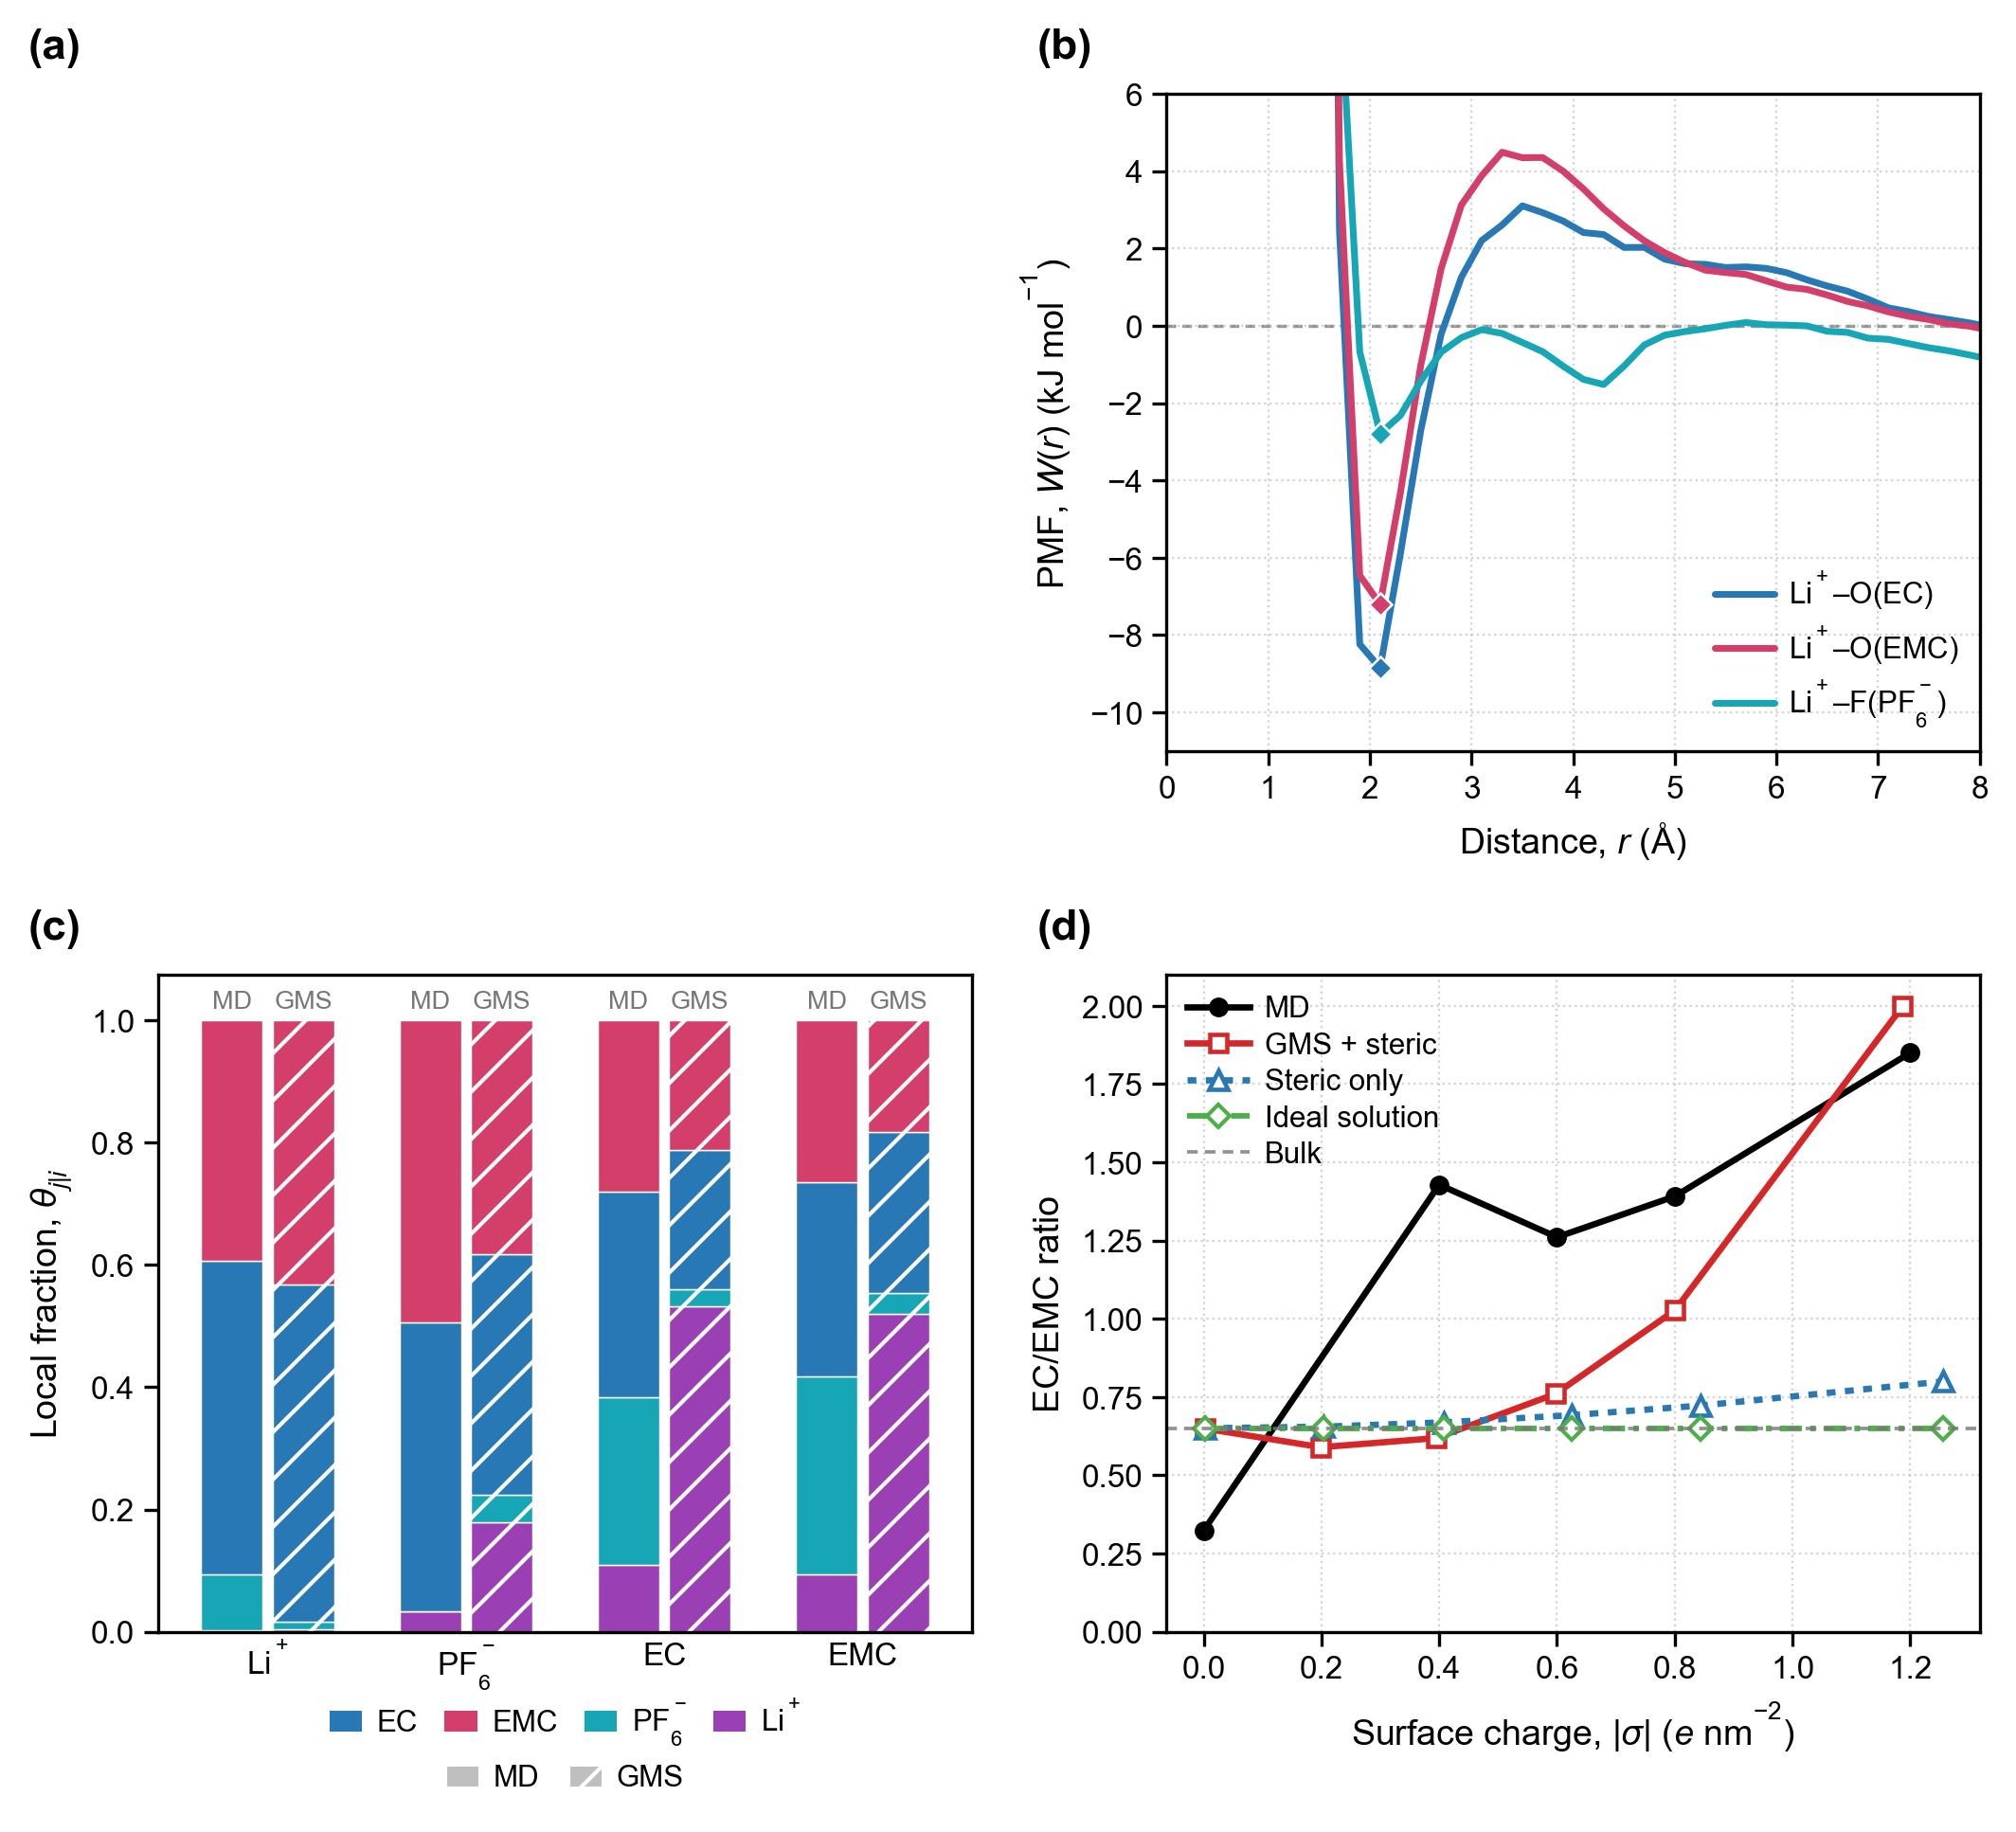

In [18]:
# ============================================================
# FIGURE 3: ACS-STYLE 2 × 2 MULTIPANEL FIGURE
# ============================================================
# ------------------------------------------------------------
# 1. GLOBAL STYLE
# ------------------------------------------------------------
# Keep all typography and line styling consistent across panels.
plt.rcParams.update({
    "font.family": "Arial",          # Falls back automatically if unavailable
    "font.size": 8.5,
    "axes.labelsize": 9,
    "axes.titlesize": 9.5,
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "legend.fontsize": 7.5,
    "legend.handlelength": 1.5,
    "legend.handletextpad": 0.5,
    "legend.borderaxespad": 0.3,
    "lines.linewidth": 1.6,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,              # Editable text in Illustrator
    "ps.fonttype": 42,
    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
})


# ------------------------------------------------------------
# 2. COLOR PALETTE
# ------------------------------------------------------------
# A restrained, colorblind-friendly palette.
COLORS = {
    "EC":  "#2878B5",
    "EMC": "#D33F6A",
    "PF6": "#16A6B6",
    "Li":  "#9B3FB5",
    "full": "#D62728",
    "steric": "#2878B5",
    "ideal": "#4DAF4A",
    "gray": "#777777",
    "light_gray": "#D9D9D9",
}


# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------
def style_axis(ax, grid=False):
    """
    Apply consistent axis styling without changing plotted data.
    """
    ax.spines["top"].set_linewidth(0.8)
    ax.spines["right"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.spines["left"].set_linewidth(0.8)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        top=False,
        right=False,
        pad=2.5
    )

    if grid:
        ax.grid(
            True,
            which="major",
            linestyle=":",
            linewidth=0.55,
            color="#BDBDBD",
            alpha=0.65
        )
        ax.set_axisbelow(True)


def add_panel_label(ax, label, x=-0.16, y=1.04):
    """
    Add a consistent multipanel label.
    """
    ax.text(
        x, y, label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        clip_on=False
    )


# ------------------------------------------------------------
# 4. FIGURE LAYOUT
# ------------------------------------------------------------
# Approximately suitable for a double-column figure.
# You may adjust height slightly after inserting the final panel-a artwork.
fig, axes = plt.subplots(
    2, 2,
    figsize=(7.2, 6.6),
    gridspec_kw={
        "wspace": 0.24,
        "hspace": 0.34
    }
)


# ============================================================
# PANEL A: MOLECULAR STRUCTURES
# ============================================================
ax = axes[0, 0]
ax.axis("off")

# Your molecular structures are inserted elsewhere into this axis.
# Keep the structure labels in the molecule-rendering code visually
# consistent with the 9–10 pt text used in the remaining panels.

add_panel_label(ax, "(a)")


# ============================================================
# PANEL B: PMF / SOLVATION ENERGETICS
# ============================================================
ax = axes[0, 1]

target_center = "Li+"

neighbors_map = {
    "EC":  "Li+-O(c_EC)",
    "EMC": "Li+-O(c_EMC)",
    "PF6": "Li+-F(PF6)"
}

kB_T = 8.314 * 293 / 1000

colors_A = {
    "EC":  COLORS["EC"],
    "EMC": COLORS["EMC"],
    "PF6": COLORS["PF6"]
}

labels_A = {
    "EC":  r"Li$^+$–O(EC)",
    "EMC": r"Li$^+$–O(EMC)",
    "PF6": r"Li$^+$–F(PF$_6^-$)"
}

if "rdf_data" in locals():

    r_vals = rdf_data["r"]

    for label, col_name in neighbors_map.items():

        if col_name in rdf_data.columns:

            # Original data transformation is unchanged.
            g_vals = np.clip(rdf_data[col_name], 1e-10, None)
            w_vals = -kB_T * np.log(g_vals)

            ax.plot(
                r_vals,
                w_vals,
                color=colors_A[label],
                linewidth=1.7,
                label=labels_A[label],
                solid_capstyle="round"
            )

            # Original minimum search range and logic are unchanged.
            mask = (r_vals > 1.5) & (r_vals < 3.5)

            if mask.any():
                min_idx = np.argmin(w_vals[mask])
                min_r = r_vals[mask].iloc[min_idx]
                min_w = w_vals[mask].iloc[min_idx]

                ax.plot(
                    min_r,
                    min_w,
                    marker="D",
                    markersize=4.2,
                    markerfacecolor=colors_A[label],
                    markeredgecolor="white",
                    markeredgewidth=0.6,
                    linestyle="none",
                    zorder=4
                )

else:
    ax.text(
        0.5, 0.5,
        "Load `rdf_data` to display PMF",
        transform=ax.transAxes,
        ha="center",
        va="center",
        color=COLORS["gray"]
    )

ax.axhline(
    0,
    color=COLORS["gray"],
    linestyle=(0, (3, 2)),
    linewidth=0.8,
    alpha=0.8,
    zorder=0
)

ax.set_xlim(0, 8)
ax.set_ylim(-11, 6)

ax.set_xlabel(r"Distance, $r$ ($\mathrm{\AA}$)")
ax.set_ylabel(r"PMF, $W(r)$ (kJ mol$^{-1}$)")

# The title is optional. Removing it generally produces a cleaner manuscript figure.
# ax.set_title(r"Li$^+$ solvation energetics", pad=5)

ax.legend(
    loc="lower right",
    frameon=False,
    handlelength=2.0,
    labelspacing=0.35
)

style_axis(ax, grid=True)
add_panel_label(ax, "(b)")


# ============================================================
# PANEL C: LOCAL SOLVATION FRACTIONS
# ============================================================
ax = axes[1, 0]

species_labels = [
    r"Li$^+$",
    r"PF$_6^-$",
    "EC",
    "EMC"
]

centers_to_plot = [0, 1, 2, 3]

color_map_B = {
    r"Li$^+$": COLORS["Li"],
    r"PF$_6^-$": COLORS["PF6"],
    "EC": COLORS["EC"],
    "EMC": COLORS["EMC"]
}

colors_B = [color_map_B[label] for label in species_labels]

width = 0.31
pair_gap = 0.025
x_pos = np.arange(len(centers_to_plot))

x_md = x_pos - width / 2 - pair_gap
x_gms = x_pos + width / 2 + pair_gap

bottom_MD = np.zeros(len(centers_to_plot))
bottom_Model = np.zeros(len(centers_to_plot))

for j in range(len(species_labels)):

    layer_MD = theta_MD[:, j]
    layer_Model = theta_model[:, j]

    # MD: solid fill
    ax.bar(
        x_md,
        layer_MD,
        width=width,
        bottom=bottom_MD,
        color=colors_B[j],
        edgecolor="white",
        linewidth=0.35
    )

    # GMS: same species colors, distinguished by hatch
    ax.bar(
        x_gms,
        layer_Model,
        width=width,
        bottom=bottom_Model,
        color=colors_B[j],
        edgecolor="white",
        linewidth=0.35,
        hatch="//"
    )

    bottom_MD += layer_MD
    bottom_Model += layer_Model


ax.set_xlim(-0.55, len(x_pos) - 0.45)
ax.set_ylim(0, 1.075)

ax.set_xticks(x_pos)
ax.set_xticklabels(species_labels)
ax.tick_params(axis="x", length=0)

ax.set_ylabel(r"Local fraction, $\theta_{j|i}$")

# Optional title; caption may be sufficient.
# ax.set_title("Solvation-shell composition", pad=5)


# MD/GMS labels above each bar pair
for x1, x2 in zip(x_md, x_gms):
    ax.text(
        x1, 1.012, "MD",
        ha="center",
        va="bottom",
        fontsize=6.5,
        color=COLORS["gray"]
    )
    ax.text(
        x2, 1.012, "GMS",
        ha="center",
        va="bottom",
        fontsize=6.5,
        color=COLORS["gray"]
    )


# Species legend
species_handles = [
    Patch(
        facecolor=color_map_B["EC"],
        edgecolor="none",
        label="EC"
    ),
    Patch(
        facecolor=color_map_B["EMC"],
        edgecolor="none",
        label="EMC"
    ),
    Patch(
        facecolor=color_map_B[r"PF$_6^-$"],
        edgecolor="none",
        label=r"PF$_6^-$"
    ),
    Patch(
        facecolor=color_map_B[r"Li$^+$"],
        edgecolor="none",
        label=r"Li$^+$"
    )
]

legend_species = ax.legend(
    handles=species_handles,
    loc="upper center",
    bbox_to_anchor=(0.50, -0.07),
    ncol=4,
    frameon=False,
    columnspacing=0.9,
    handlelength=1.1
)

ax.add_artist(legend_species)

# Encoding legend: solid versus hatched
method_handles = [
    Patch(
        facecolor="#BFBFBF",
        edgecolor="white",
        linewidth=0.25,
        label="MD"
    ),
    Patch(
        facecolor="#BFBFBF",
        edgecolor="white",
        linewidth=0.25,
        hatch="//",
        label="GMS"
    )
]

ax.legend(
    handles=method_handles,
    loc="upper center",
    bbox_to_anchor=(0.50, -0.17),
    ncol=2,
    frameon=False,
    columnspacing=1.0,
    handlelength=1.1
)

style_axis(ax, grid=False)
add_panel_label(ax, "(c)")


# ============================================================
# PANEL D: INTERFACIAL EC/EMC RATIO
# ============================================================
ax = axes[1, 1]

# 1. MD data
ax.plot(
    df_md["Charge_Density_abs"],
    df_md["Ratio_EC_EMC"],
    marker="o",
    markersize=4.4,
    markerfacecolor="black",
    markeredgecolor="black",
    markeredgewidth=0.6,
    color="black",
    linestyle="-",
    linewidth=1.6,
    label="MD"
)

# 2. Full model
if not df_full.empty:
    ax.plot(
        df_full["sigma_abs"],
        df_full["Ratio"],
        marker="s",
        markersize=4.4,
        markerfacecolor="white",
        markeredgecolor=COLORS["full"],
        markeredgewidth=1.1,
        color=COLORS["full"],
        linestyle="-",
        linewidth=1.6,
        label="GMS + steric"
    )

# 3. Steric-only model
if not df_steric.empty:
    ax.plot(
        df_steric["sigma_abs"],
        df_steric["Ratio"],
        marker="^",
        markersize=4.6,
        markerfacecolor="white",
        markeredgecolor=COLORS["steric"],
        markeredgewidth=1.1,
        color=COLORS["steric"],
        linestyle=(0, (1.4, 1.5)),
        linewidth=1.6,
        label="Steric only"
    )

# 4. Ideal-solution model
ax.plot(
    df_steric["sigma_abs"],
    np.full_like(df_steric["sigma_abs"], bulk_ratio),
    marker="D",
    markersize=4.2,
    markerfacecolor="white",
    markeredgecolor=COLORS["ideal"],
    markeredgewidth=1.0,
    color=COLORS["ideal"],
    linestyle=(0, (4, 1.5, 1, 1.5)),
    linewidth=1.4,
    label="Ideal solution"
)

# Bulk reference line
ax.axhline(
    bulk_ratio,
    color=COLORS["gray"],
    linestyle=(0, (3, 2)),
    linewidth=0.9,
    alpha=0.8,
    label="Bulk"
)

ax.set_xlabel(r"Surface charge, $|\sigma|$ ($e$ nm$^{-2}$)")
ax.set_ylabel("EC/EMC ratio")
ax.set_ylim(0, 2.1)

# Again, the panel title can be moved to the caption.
# ax.set_title("EC/EMC ratio in the negative EDL", pad=5)

ax.legend(
    loc="upper left",
    frameon=False,
    labelspacing=0.30,
    handlelength=2.1
)

style_axis(ax, grid=True)
add_panel_label(ax, "(d)")


# ------------------------------------------------------------
# 5. FINAL SPACING
# ------------------------------------------------------------
# Manual adjustment is more reliable than tight_layout for a figure
# containing an artwork panel and legends below panel c.
fig.subplots_adjust(
    left=0.095,
    right=0.985,
    top=0.965,
    bottom=0.145,
    wspace=0.27,
    hspace=0.34
)


# ------------------------------------------------------------
# 6. EXPORT
# ------------------------------------------------------------
# Vector PDF is preferred for plots and text.
# Raster molecular structures embedded in panel a will retain their
# original raster resolution.
#
# fig.savefig(
#     "Figure_3_JACS.pdf",
#     bbox_inches="tight",
#     pad_inches=0.02
# )
#
# fig.savefig(
#     "Figure_3_JACS.tif",
#     dpi=600,
#     bbox_inches="tight",
#     pad_inches=0.02,
#     pil_kwargs={"compression": "tiff_lzw"}
# )
# plt.savefig('Figure_3_Revised_2x2_v2.png', dpi=500, bbox_inches='tight')

plt.show()